# 01 – Exploratory data analysis
Irish grid (ROI) CO₂ intensity, wind, demand and Open-Meteo 24 h-ahead wind forecasts, hourly, UTC.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="talk", font_scale=0.8, font="DejaVu Sans")  # DejaVu has the ₂ glyph
df = pd.read_csv(ROOT / "data/processed/clean_hourly.csv", parse_dates=["time_utc"]).set_index("time_utc")
df = df[df.index >= "2024-06-01"]  # drop the single 23:00 UTC hour from 31 May
local = df.index.tz_convert("Europe/Dublin")
df["season"] = pd.Categorical(local.month.map({12:"Winter",1:"Winter",2:"Winter",3:"Spring",4:"Spring",5:"Spring",
    6:"Summer",7:"Summer",8:"Summer",9:"Autumn",10:"Autumn",11:"Autumn"}), ["Winter","Spring","Summer","Autumn"])
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=300); plt.show()

## 1. Dataset description

In [2]:
desc = pd.DataFrame([
    ["EirGrid Smart Grid Dashboard (ROI)", "CO₂ intensity, CO₂ emissions, wind, demand, solar", "15-min → hourly mean"],
    ["Open-Meteo Previous Model Runs", "100 m wind speed, 24 h-ahead forecast + near-actual, 4 sites", "hourly"],
], columns=["source", "variables", "resolution"])
desc["period (UTC)"] = f"{df.index.min():%Y-%m-%d} → {df.index.max():%Y-%m-%d}"
desc["rows"] = len(df); desc["features"] = df.shape[1] - 1
desc["CO₂ intensity missing %"] = round(df.co2_intensity.isna().mean() * 100, 2)
desc["CO₂ intensity filled (emissions/demand)"] = int(df.co2_intensity_filled.sum())
desc.to_csv(RES / "dataset_description.csv", index=False); desc.T

,0,1
source,EirGrid Smart Grid Dashboard (ROI),Open-Meteo Previous Model Runs
variables,"CO₂ intensity, CO₂ emissions, wind, demand, solar","100 m wind speed, 24 h-ahead forecast + near-a..."
resolution,15-min → hourly mean,hourly
period (UTC),2024-06-01 → 2026-11-02,2024-06-01 → 2026-11-02
rows,21240,21240
features,21,21
CO₂ intensity missing %,3.34,3.34
CO₂ intensity filled (emissions/demand),2409,2409


**What it shows:** ~21,200 hourly rows from June 2024 to early November 2026. The target (CO₂ intensity) is missing for only 3.3% of hours; ~2,400 hours were derived from emissions ÷ demand where EirGrid did not publish intensity. Open-Meteo wind data is complete.

## 2. Summary statistics

In [3]:
cols = ["co2_intensity", "co2_emissions_t_per_h", "wind_mw", "demand_mw", "solar_mw", "wind_share",
        "wind100_fc_mean", "wind100_act_mean"]
stats = df[cols].describe().T.round(2)
stats["missing_%"] = (df[cols].isna().mean() * 100).round(2)
stats.to_csv(RES / "summary_stats.csv"); stats

,count,mean,std,min,25%,50%,75%,max,missing_%
co2_intensity,20530.0,195.29,63.89,21.67,144.25,191.00,237.50,471.25,3.34
co2_emissions_t_per_h,16510.0,809.02,259.67,450.00,607.75,777.50,949.00,2428.50,22.27
wind_mw,21234.0,1274.93,886.97,0.25,520.31,1104.25,1925.81,3858.75,0.03
demand_mw,20778.0,3933.98,576.77,2673.25,3499.31,3901.62,4296.19,5965.25,2.18
solar_mw,12752.0,172.00,257.25,-166.00,0.00,16.50,279.75,1256.50,39.96
wind_share,20778.0,0.32,0.22,0.00,0.13,0.29,0.49,1.00,2.18
wind100_fc_mean,21240.0,7.98,3.36,0.52,5.58,7.57,9.95,28.50,0.00
wind100_act_mean,21240.0,7.89,3.30,0.85,5.48,7.50,9.90,28.15,0.00


**What it shows:** mean CO₂ intensity is ~195 g/kWh but ranges from ~22 to ~471 g/kWh, so there is large room to shift load. Wind supplies ~32% of demand on average with very high variability. Solar is only reported from May 2025 (40% missing) and has small negative values (metering artefacts), so it is not used as a model input.

## 3. CO₂ intensity by hour of day, per season

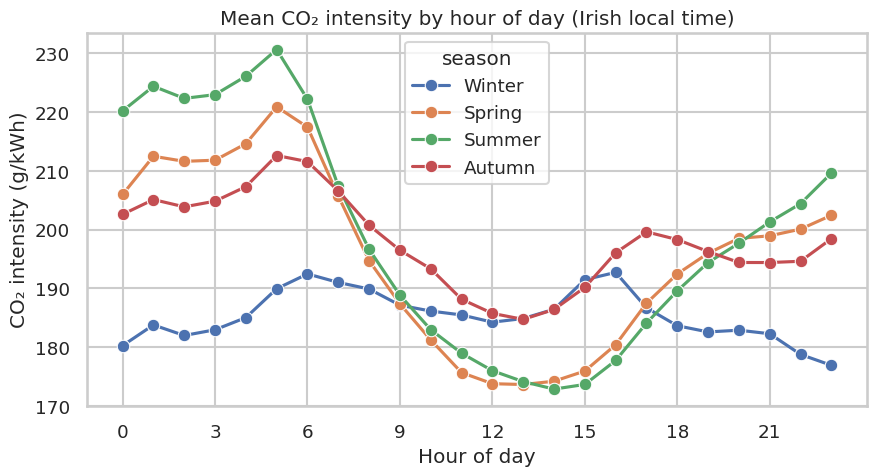

hour_local,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
season,,,,,,,,,,,,,,,,,,,,,
Winter,180.0,184.0,182.0,183.0,185.0,190.0,192.0,191.0,190.0,187.0,...,186.0,191.0,193.0,187.0,184.0,183.0,183.0,182.0,179.0,177.0
Spring,206.0,212.0,212.0,212.0,215.0,221.0,217.0,206.0,195.0,187.0,...,174.0,176.0,180.0,187.0,192.0,196.0,199.0,199.0,200.0,202.0
Summer,220.0,224.0,222.0,223.0,226.0,231.0,222.0,207.0,197.0,189.0,...,173.0,174.0,178.0,184.0,190.0,194.0,198.0,201.0,204.0,210.0
Autumn,203.0,205.0,204.0,205.0,207.0,213.0,212.0,207.0,201.0,197.0,...,186.0,190.0,196.0,200.0,198.0,196.0,194.0,194.0,195.0,198.0


In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=df.assign(hour_local=local.hour), x="hour_local", y="co2_intensity", hue="season",
             estimator="mean", errorbar=None, ax=ax, marker="o")
ax.set(title="Mean CO₂ intensity by hour of day (Irish local time)", xlabel="Hour of day", ylabel="CO₂ intensity (g/kWh)")
ax.set_xticks(range(0, 24, 3)); save(fig, "co2_by_hour_season.png")
df.assign(hour_local=local.hour).pivot_table(index="hour_local", columns="season", values="co2_intensity", observed=True).round(0).T

**What it shows:** in spring and summer the grid is cleanest in the early afternoon (~173–176 g/kWh at 14:00–15:00, solar + wind) and dirtiest around 05:00 (~221–231 g/kWh). In winter the daily curve is flat (~177–193 g/kWh), so savings from shifting depend mostly on day-to-day wind, not on the clock — a fixed 'run at night' rule is not enough.

## 4. CO₂ intensity vs wind share

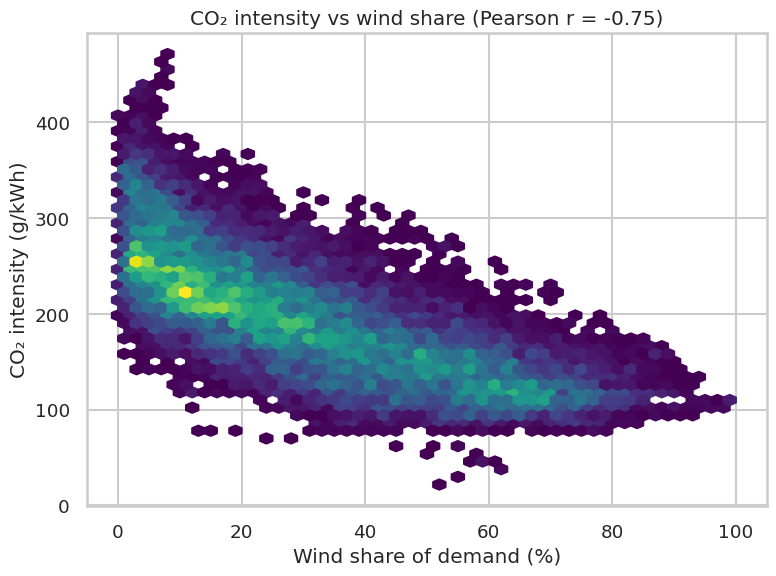

Pearson r = -0.747, n = 20122


In [5]:
d = df[["wind_share", "co2_intensity"]].dropna()
r = d.corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.hexbin(d.wind_share * 100, d.co2_intensity, gridsize=50, cmap="viridis", mincnt=1)
ax.set(title=f"CO₂ intensity vs wind share (Pearson r = {r:.2f})", xlabel="Wind share of demand (%)", ylabel="CO₂ intensity (g/kWh)")
save(fig, "co2_vs_wind_share.png"); print(f"Pearson r = {r:.3f}, n = {len(d)}")

**What it shows:** a strong negative relationship (r ≈ −0.75, so wind share alone explains ~56% of the variance): the more of demand met by wind, the cleaner the grid. This is the main reason we expect wind *forecasts* (feature set B) to improve 24 h-ahead CO₂ prediction.

## 5. Monthly CO₂ intensity trend

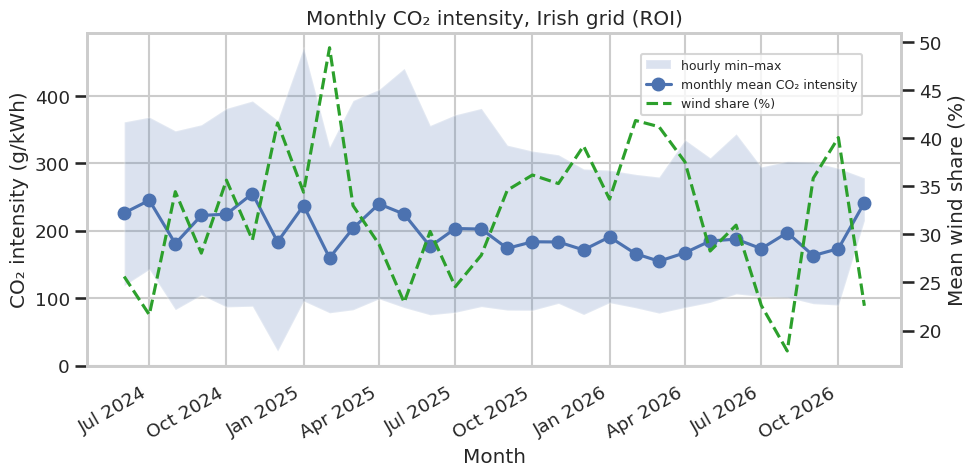

,mean,wind_share_%
time_utc,,
2024-06-01 00:00:00+00:00,226.0,25.6
2024-07-01 00:00:00+00:00,245.0,21.6
2024-08-01 00:00:00+00:00,181.0,34.4
2024-09-01 00:00:00+00:00,223.0,28.0
2024-10-01 00:00:00+00:00,224.0,35.6
2024-11-01 00:00:00+00:00,255.0,29.4
2024-12-01 00:00:00+00:00,183.0,41.6
2025-01-01 00:00:00+00:00,237.0,34.4
2025-02-01 00:00:00+00:00,160.0,49.4


In [6]:
m = df.co2_intensity.resample("MS").agg(["mean", "min", "max"])
m2 = df.wind_share.resample("MS").mean() * 100
fig, ax = plt.subplots(figsize=(10, 5))
ax.fill_between(m.index, m["min"], m["max"], alpha=0.2, label="hourly min–max")
ax.plot(m.index, m["mean"], marker="o", label="monthly mean CO₂ intensity")
ax.set(title="Monthly CO₂ intensity, Irish grid (ROI)", xlabel="Month", ylabel="CO₂ intensity (g/kWh)")
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax2 = ax.twinx(); ax2.plot(m2.index, m2, color="tab:green", ls="--", label="wind share (%)"); ax2.set_ylabel("Mean wind share (%)"); ax2.grid(False)
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88), fontsize=9); save(fig, "co2_monthly_trend.png")
pd.concat([m["mean"].round(0), m2.round(1).rename("wind_share_%")], axis=1)

**What it shows:** monthly mean intensity moves opposite to wind share (e.g. Feb 2025: 49% wind, 160 g/kWh; Nov 2024: 29% wind, 255 g/kWh). Months in 2026 are generally cleaner than 2024 (mostly 155–197 vs 181–255 g/kWh). The last point (Nov 2026) covers only 2 days.

## 6. 24 h-ahead wind forecast accuracy

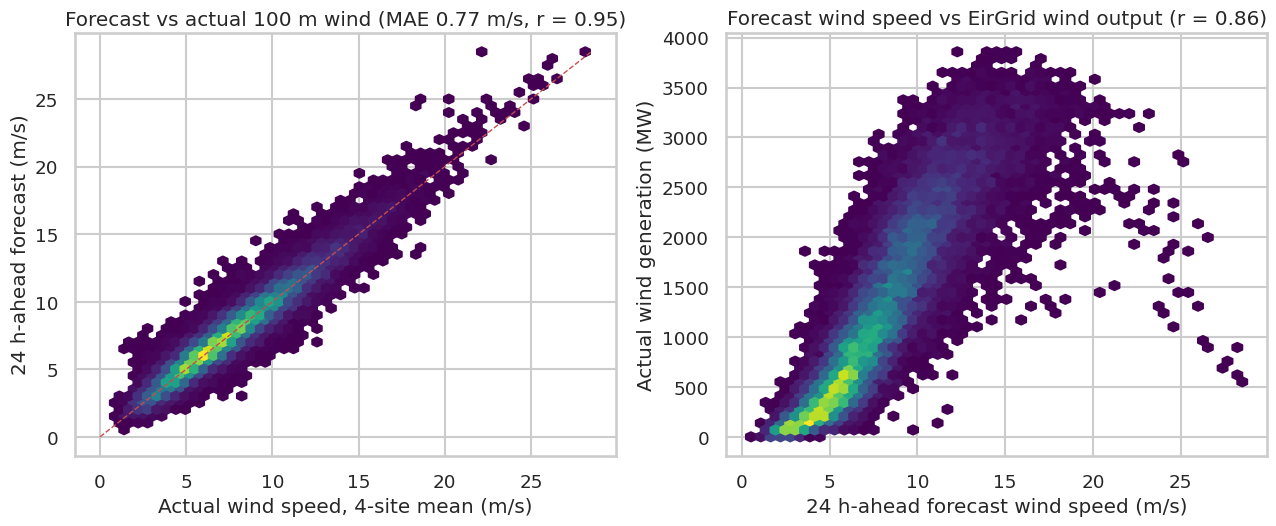

MAE = 0.774 m/s, r(fc, actual speed) = 0.952, r(fc, wind MW) = 0.863


In [7]:
d = df[["wind100_fc_mean", "wind100_act_mean", "wind_mw"]].dropna()
mae = (d.wind100_fc_mean - d.wind100_act_mean).abs().mean()
r_ws = d.wind100_fc_mean.corr(d.wind100_act_mean); r_mw = d.wind100_fc_mean.corr(d.wind_mw)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].hexbin(d.wind100_act_mean, d.wind100_fc_mean, gridsize=50, cmap="viridis", mincnt=1)
lim = [0, d[["wind100_fc_mean", "wind100_act_mean"]].max().max()]; axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set(title=f"Forecast vs actual 100 m wind (MAE {mae:.2f} m/s, r = {r_ws:.2f})",
            xlabel="Actual wind speed, 4-site mean (m/s)", ylabel="24 h-ahead forecast (m/s)")
axes[1].hexbin(d.wind100_fc_mean, d.wind_mw, gridsize=50, cmap="viridis", mincnt=1)
axes[1].set(title=f"Forecast wind speed vs EirGrid wind output (r = {r_mw:.2f})",
            xlabel="24 h-ahead forecast wind speed (m/s)", ylabel="Actual wind generation (MW)")
save(fig, "wind_forecast_accuracy.png")
print(f"MAE = {mae:.3f} m/s, r(fc, actual speed) = {r_ws:.3f}, r(fc, wind MW) = {r_mw:.3f}")

**What it shows:** the 24 h-ahead forecast is close to the realised wind (MAE ≈ 0.77 m/s, r ≈ 0.95) and correlates strongly with actual Irish wind generation (r ≈ 0.86). So a forecast that is legitimately available a day ahead carries most of the wind signal — without leaking future information.